<a href="https://colab.research.google.com/github/BluFox1210/Cancer-Detection-with-Machine-Learning/blob/Unsupervised-models/notebooks/FinalProject_ML_Unsupervised_models_WEEK1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import the necessary libraries
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

#load Wisconsin Breast Cancer dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("\nFirst 5 rows:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (569, 30)

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst 

In [28]:
#Dataset 1 missing values
wisconsin = X.copy()
wisconsin["diagnosis"] = y.map({0: "malignant", 1: "benign"})
print("\nMissing values: ")
print(wisconsin.isnull().sum().sum())


Missing values: 
0


In [29]:
#Dataset 1: class balance
print("\nClass Balance: ")
print(wisconsin["diagnosis"].value_counts())

print("\nClass Balance Percentage: ")
print(wisconsin["diagnosis"].value_counts(normalize=True) * 100)


Class Balance: 
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Class Balance Percentage: 
diagnosis
benign       62.741652
malignant    37.258348
Name: proportion, dtype: float64


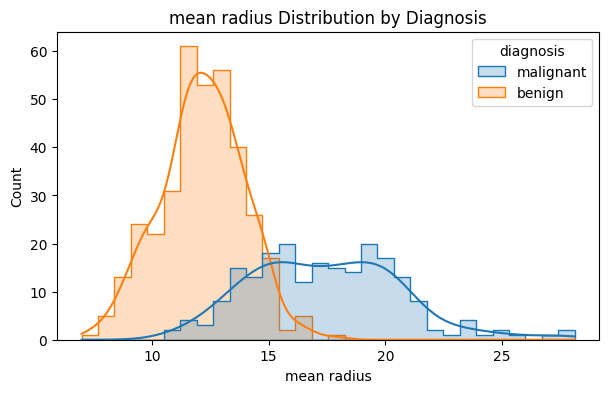

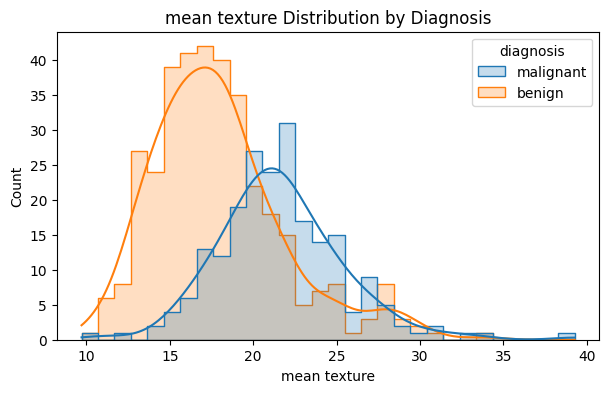

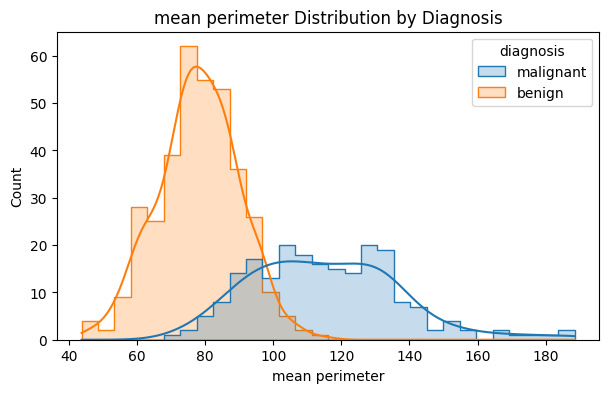

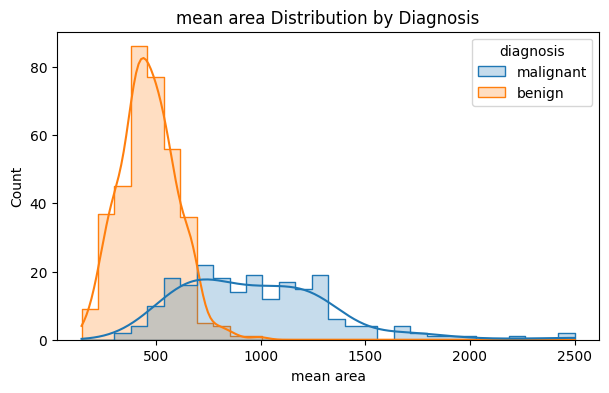

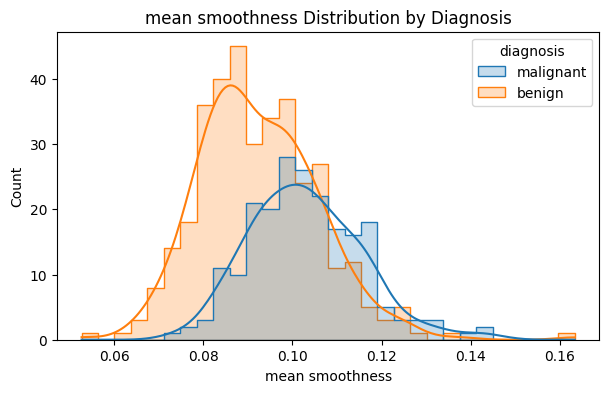

In [23]:
#Dataset 1: EDA
from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

wisconsin = X.copy()
wisconsin["diagnosis"] = y.map({0: "malignant", 1: "benign"})

features_to_plot = ["mean radius", "mean texture",
                    "mean perimeter", "mean area", "mean smoothness"]

for feature in features_to_plot:
  plt.figure(figsize=(7, 4))

  sns.histplot(
      data = wisconsin,
      x = feature,
      hue = "diagnosis",
      kde = True,
      bins = 30,
      element = "step"
  )

  plt.title(f"{feature} Distribution by Diagnosis")
  plt.show()

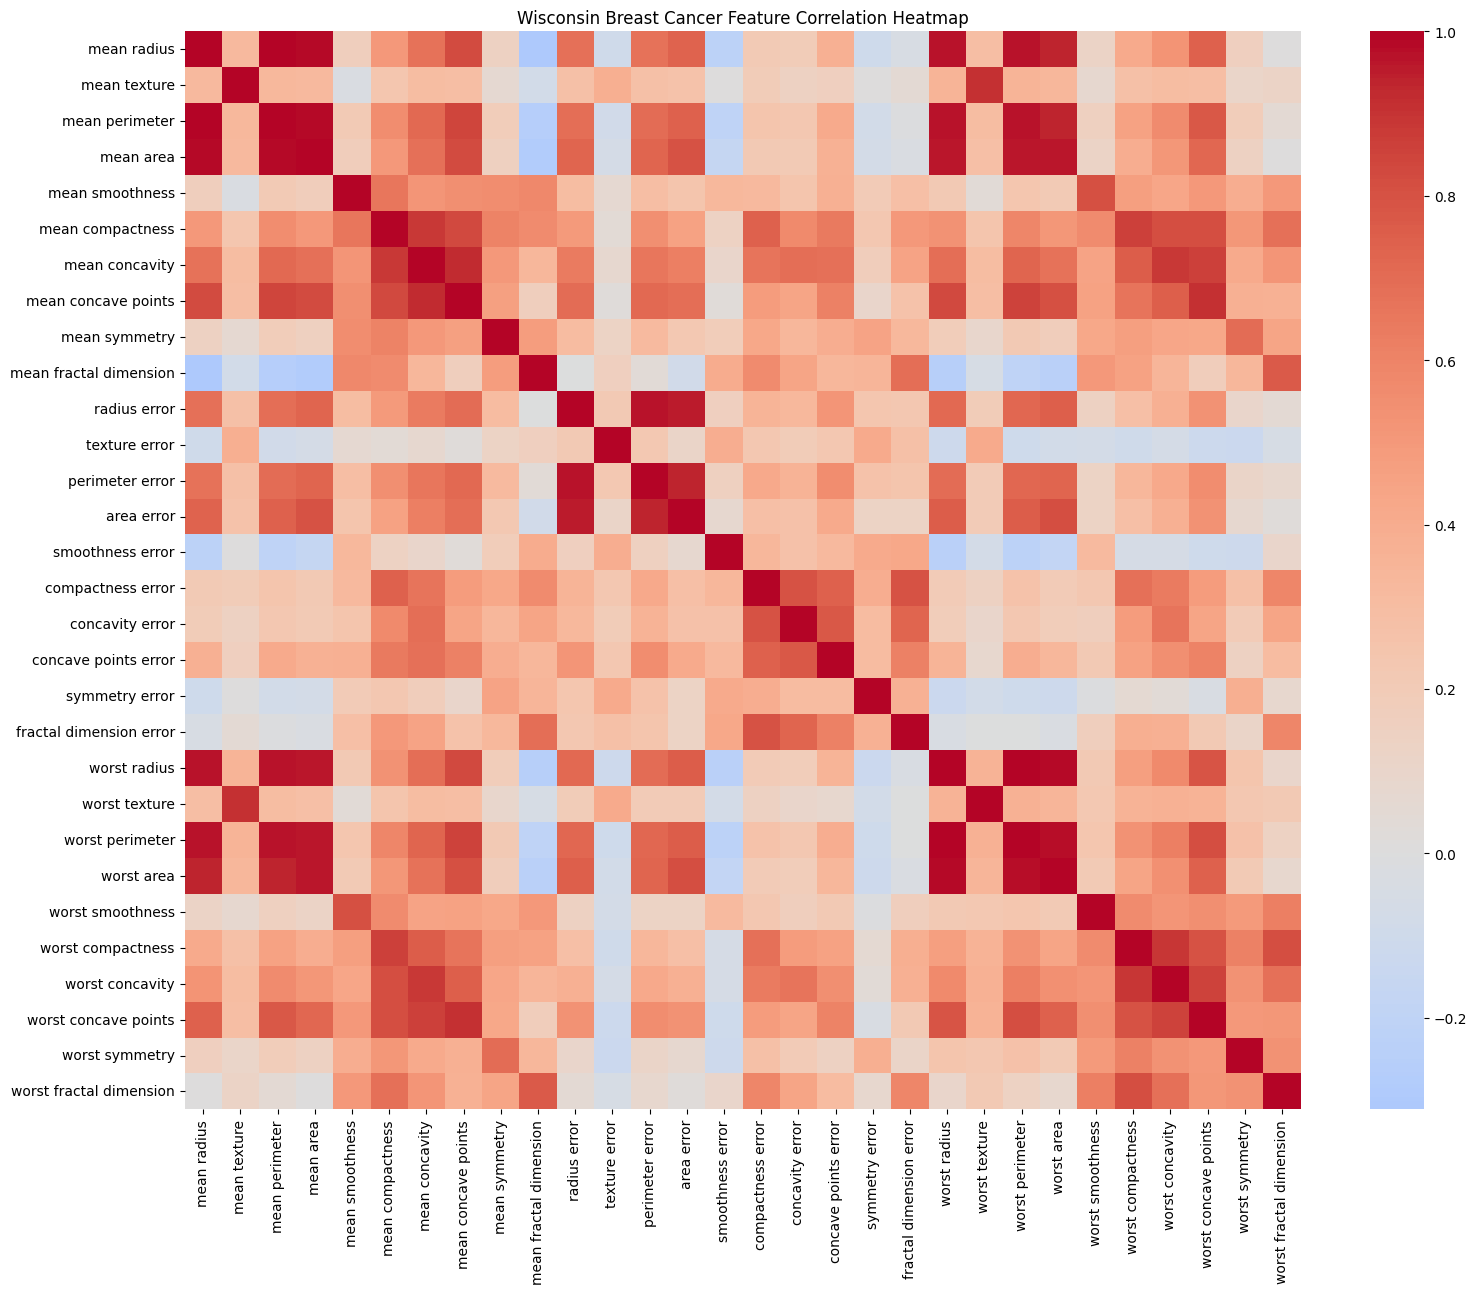

In [24]:
#Dataset 1 heatmap
correlation = X.corr()

plt.figure(figsize=(18,14))

sns.heatmap(
    correlation,
    cmap = "coolwarm",
    center = 0
)

plt.title("Wisconsin Breast Cancer Feature Correlation Heatmap")
plt.show()

In [25]:
#dataset 1: pairplot of the 5 most correlated features
target_correlation = X.corrwith(y).abs()

top5_features = target_correlation.sort_values(
    ascending = False
).head(5).index.tolist()

print("Top 5 Features: ", top5_features)

Top 5 Features:  ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter']


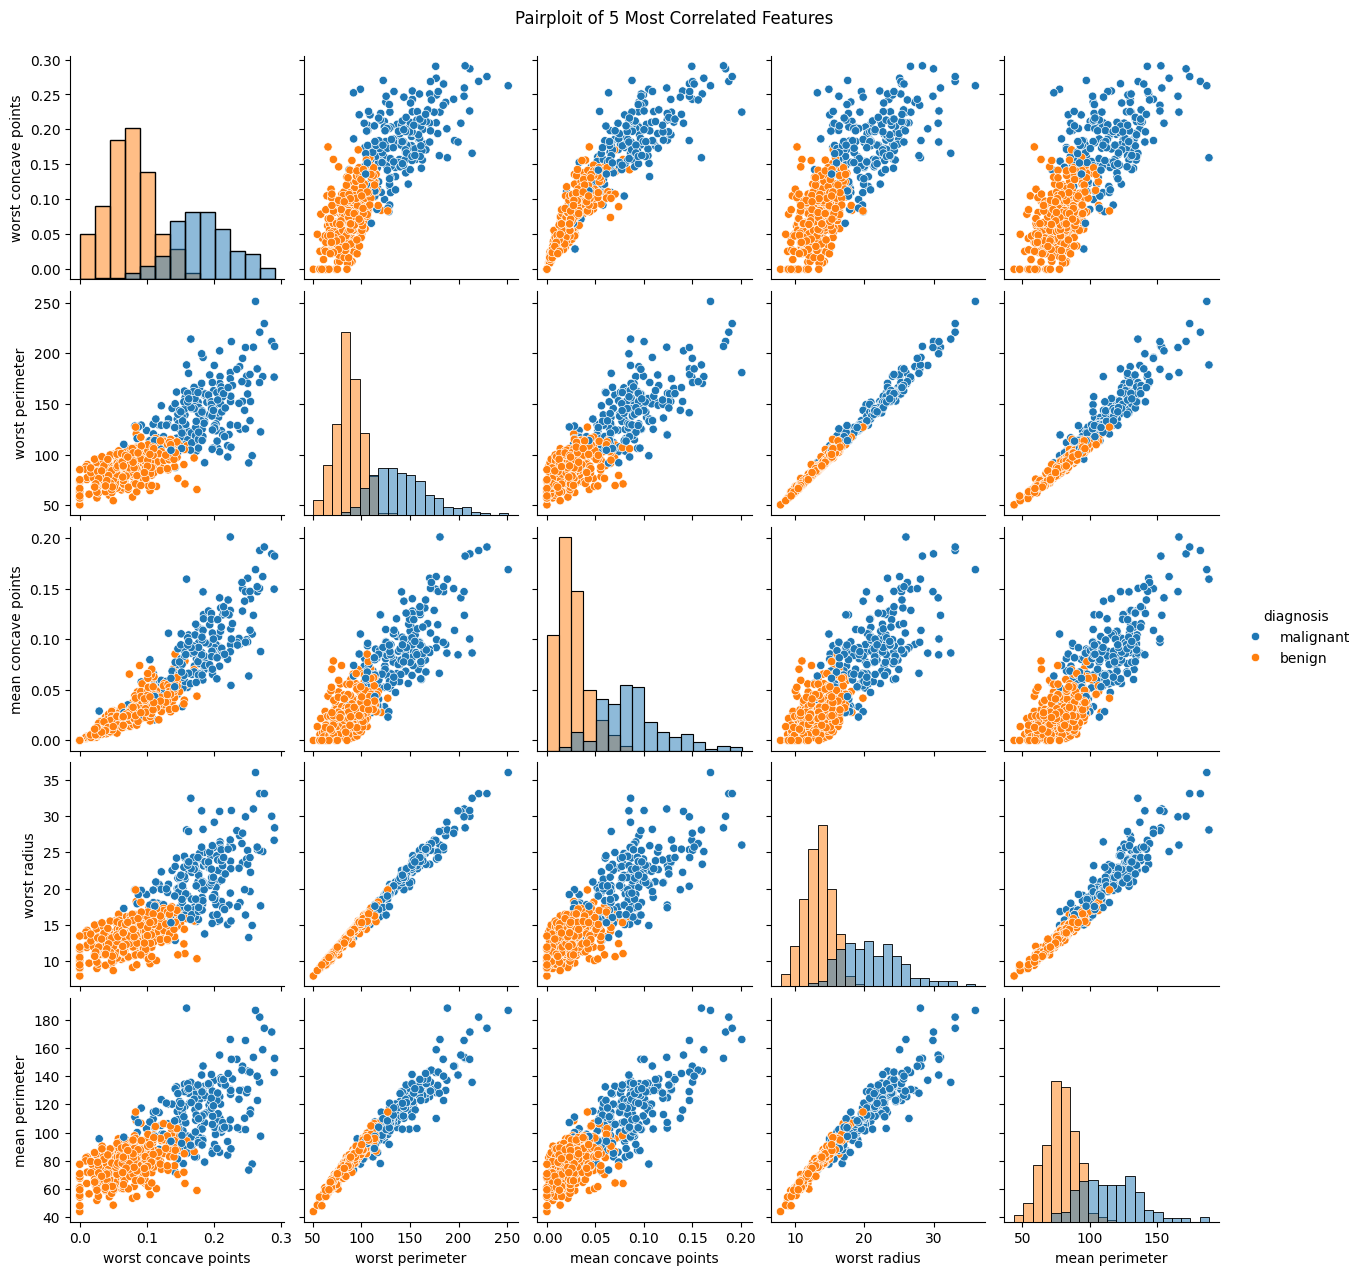

In [26]:
pairplot_data = wisconsin[top5_features + ["diagnosis"]]

sns.pairplot(
    pairplot_data,
    hue = "diagnosis",
    diag_kind = "hist"
)

plt.suptitle("Pairploit of 5 Most Correlated Features", y = 1.02)
plt.show()

In [34]:
!kaggle datasets download \
    -d raghadalharbi/breast-cancer-gene-expression-profiles-metabric \
    -p /content/data/metabric \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/raghadalharbi/breast-cancer-gene-expression-profiles-metabric
License(s): DbCL-1.0
100% 2.72M/2.72M [00:00<00:00, 119MB/s]



In [35]:
##Dataset 2: METABRIC
import pandas as pd
import numpy as np

metabric = pd.read_csv("/content/data/metabric/METABRIC_RNA_Mutation.csv", low_memory = False)

print("Dataset shape:", metabric.shape)
metabric.head()

Dataset shape: (1904, 693)


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


In [36]:
#dataset dimensions for dataset 2
print("Rows:", metabric.shape[0])
print("Columns:", metabric.shape[1])

Rows: 1904
Columns: 693


In [37]:
#dataset 2 data types
metabric.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Columns: 693 entries, patient_id to siah1_mut
dtypes: float64(498), int64(5), object(190)
memory usage: 10.1+ MB


In [38]:
#dataset 2 missing values
missing_values = metabric.isnull().sum()
print(missing_values[missing_values > 0].sort_values(ascending = False))

print("\nTotal missing values:")
print(metabric.isnull().sum().sum())

tumor_stage                       501
3-gene_classifier_subtype         204
primary_tumor_laterality          106
neoplasm_histologic_grade          72
cellularity                        54
mutation_count                     45
er_status_measured_by_ihc          30
type_of_breast_surgery             22
tumor_size                         20
cancer_type_detailed               15
tumor_other_histologic_subtype     15
oncotree_code                      15
death_from_cancer                   1
dtype: int64

Total missing values:
1100


In [ ]:
#dataset 2 basic statistics
metabric.describe()

,patient_id,age_at_diagnosis,chemotherapy,cohort,neoplasm_histologic_grade,hormone_therapy,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,overall_survival_months,...,srd5a1,srd5a2,srd5a3,st7,star,tnk2,tulp4,ugt2b15,ugt2b17,ugt2b7
count,1904.000000,1904.000000,1904.000000,1904.000000,1832.000000,1904.000000,1904.000000,1859.000000,1904.000000,1904.000000,...,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03
mean,3921.982143,61.087054,0.207983,2.643908,2.415939,0.616597,2.002101,5.697687,4.033019,125.121324,...,4.726891e-07,-3.676471e-07,-9.453782e-07,-1.050420e-07,-0.000002,3.676471e-07,4.726891e-07,7.878151e-07,0.000000,3.731842e-18
std,2358.478332,12.978711,0.405971,1.228615,0.650612,0.486343,4.079993,4.058778,1.144492,76.334148,...,1.000263e+00,1.000262e+00,1.000262e+00,1.000263e+00,1.000262,1.000264e+00,1.000262e+00,1.000263e+00,1.000262,1.000262e+00
min,0.000000,21.930000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,-2.120800e+00,-3.364800e+00,-2.719400e+00,-4.982700e+00,-2.981700,-3.833300e+00,-3.609300e+00,-1.166900e+00,-2.112600,-1.051600e+00
25%,896.500000,51.375000,0.000000,1.000000,2.000000,0.000000,0.000000,3.000000,3.046000,60.825000,...,-6.188500e-01,-6.104750e-01,-6.741750e-01,-6.136750e-01,-0.632900,-6.664750e-01,-7.102000e-01,-5.058250e-01,-0.476200,-7.260000e-01
50%,4730.500000,61.770000,0.000000,3.000000,3.000000,1.000000,0.000000,5.000000,4.042000,115.616667,...,-2.456500e-01,-4.690000e-02,-1.422500e-01,-5.175000e-02,-0.026650,7.000000e-04,-2.980000e-02,-2.885500e-01,-0.133400,-4.248000e-01
75%,5536.250000,70.592500,0.000000,3.000000,3.000000,1.000000,2.000000,7.000000,5.040250,184.716667,...,3.306000e-01,5.144500e-01,5.146000e-01,5.787750e-01,0.590350,6.429000e-01,5.957250e-01,6.022500e-02,0.270375,4.284000e-01
max,7299.000000,96.290000,1.000000,5.000000,3.000000,1.000000,45.000000,80.000000,6.360000,355.200000,...,6.534900e+00,1.027030e+01,6.329000e+00,4.571300e+00,12.742300,3.938800e+00,3.833400e+00,1.088490e+01,12.643900,3.284400e+00


In [ ]:
#dataset 2 column names
print(metabric.columns.tolist())

['patient_id', 'age_at_diagnosis', 'type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'chemotherapy', 'pam50_+_claudin-low_subtype', 'cohort', 'er_status_measured_by_ihc', 'er_status', 'neoplasm_histologic_grade', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'hormone_therapy', 'inferred_menopausal_state', 'integrative_cluster', 'primary_tumor_laterality', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'oncotree_code', 'overall_survival_months', 'overall_survival', 'pr_status', 'radio_therapy', '3-gene_classifier_subtype', 'tumor_size', 'tumor_stage', 'death_from_cancer', 'brca1', 'brca2', 'palb2', 'pten', 'tp53', 'atm', 'cdh1', 'chek2', 'nbn', 'nf1', 'stk11', 'bard1', 'mlh1', 'msh2', 'msh6', 'pms2', 'epcam', 'rad51c', 'rad51d', 'rad50', 'rb1', 'rbl1', 'rbl2', 'ccna1', 'ccnb1', 'cdk1', 'ccne1', 'cdk2', 'cdc25a', 'ccnd1', 'cdk4', 'cdk6', 'ccnd2', 'cdkn2a', 'cdkn2b', 'myc', 'cdkn1a', 'cdkn1

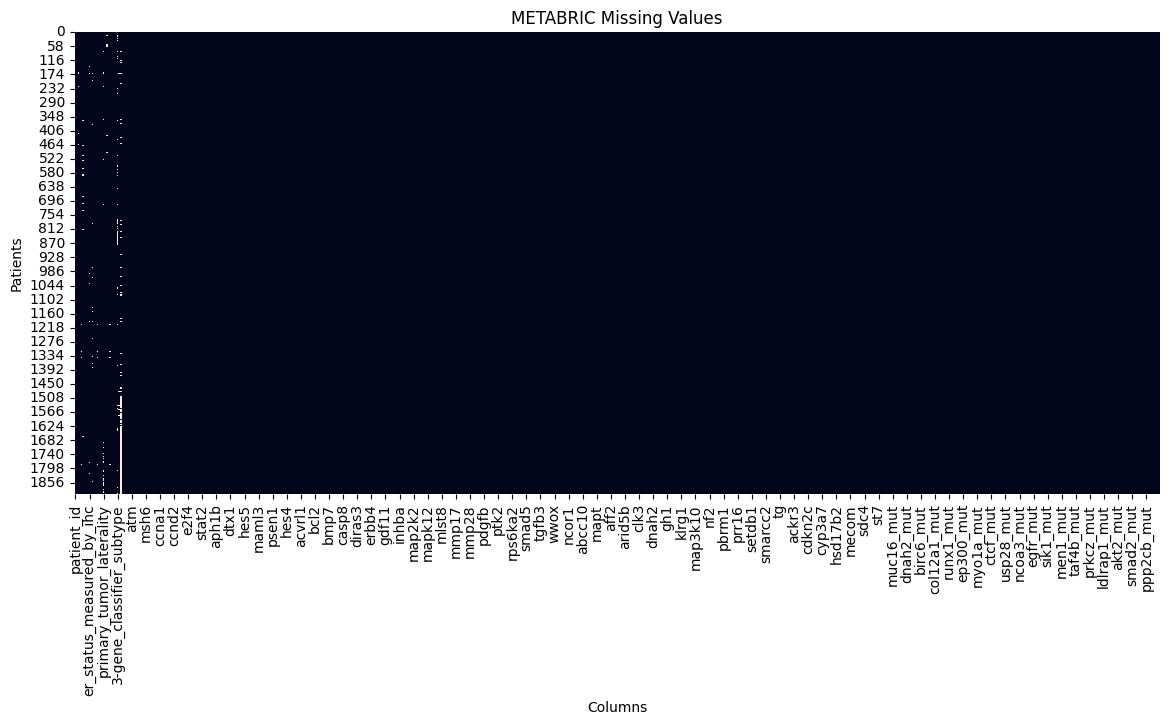

In [ ]:
#dataset 2 visualizations
import matplotlib.pyplot as plt
import seaborn as sns

#missing value map
plt.figure(figsize = (14, 6))
sns.heatmap(metabric.isnull(), cbar = False)
plt.title("METABRIC Missing Values")
plt.xlabel("Columns")
plt.ylabel("Patients")
plt.show()

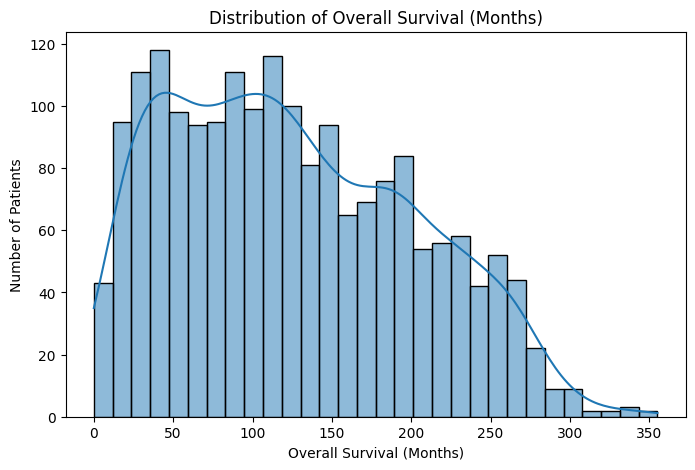

In [ ]:
#dataset 2 Overall survival months column plt
plt.figure(figsize=(8,5))
sns.histplot(
    data=metabric,
    x = "overall_survival_months",
    bins = 30,
    kde=True
)

plt.title("Distribution of Overall Survival (Months)")
plt.xlabel("Overall Survival (Months)")
plt.ylabel("Number of Patients")
plt.show()

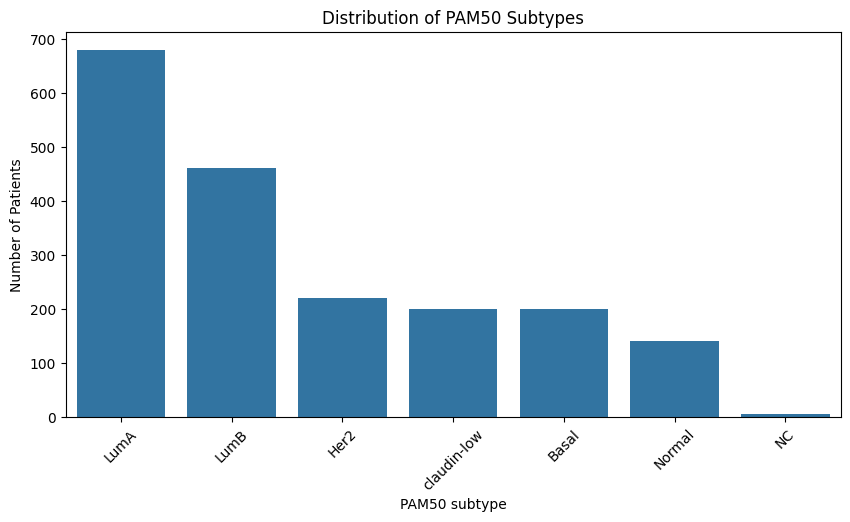

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data = metabric,
    x = "pam50_+_claudin-low_subtype",
    order = metabric["pam50_+_claudin-low_subtype"].value_counts().index
)

plt.title("Distribution of PAM50 Subtypes")
plt.xlabel("PAM50 subtype")
plt.ylabel("Number of Patients")
plt.xticks(rotation = 45)
plt.show()

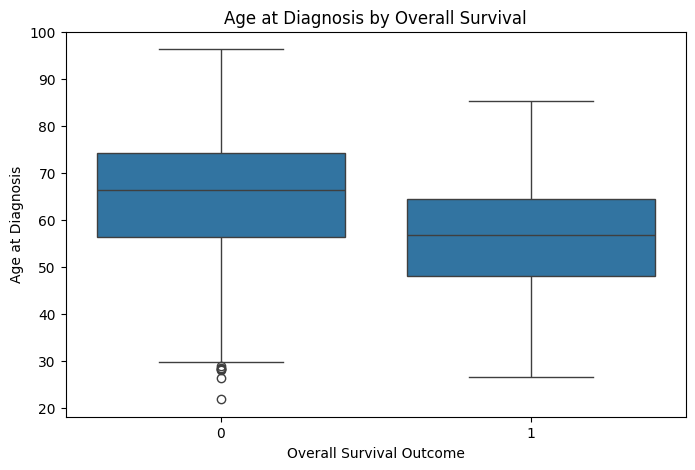

In [ ]:
#dataset 2 age at diagnosis plt
plt.figure(figsize=(8, 5))
sns.boxplot(
    data = metabric,
    x = "overall_survival",
    y = "age_at_diagnosis"
)

plt.title("Age at Diagnosis by Overall Survival")
plt.xlabel("Overall Survival Outcome")
plt.ylabel("Age at Diagnosis")
plt.show()

In [16]:
##Dataset 3 Histopathologic Cancer Detection (PatchCamelyon)
import zipfile

labels_zip = "/content/data/patchcamelyon/train_labels.csv.zip"

with zipfile.ZipFile(labels_zip, "r") as zip_ref:
    zip_ref.extractall("/content/data/patchcamelyon")

Labels shape: (220025, 2)


,id,label
0,f38a6374c348f90b587e046aac6079959adf3835,0
1,c18f2d887b7ae4f6742ee445113fa1aef383ed77,1
2,755db6279dae599ebb4d39a9123cce439965282d,0
3,bc3f0c64fb968ff4a8bd33af6971ecae77c75e08,0
4,068aba587a4950175d04c680d38943fd488d6a9d,0


In [14]:
print(labels["label"].value_counts())

print("\nClass percentages:")
print(labels["label"].value_counts(normalize=True) * 100)

label
0    130908
1     89117
Name: count, dtype: int64

Class percentages:
label
0    59.496875
1    40.503125
Name: proportion, dtype: float64


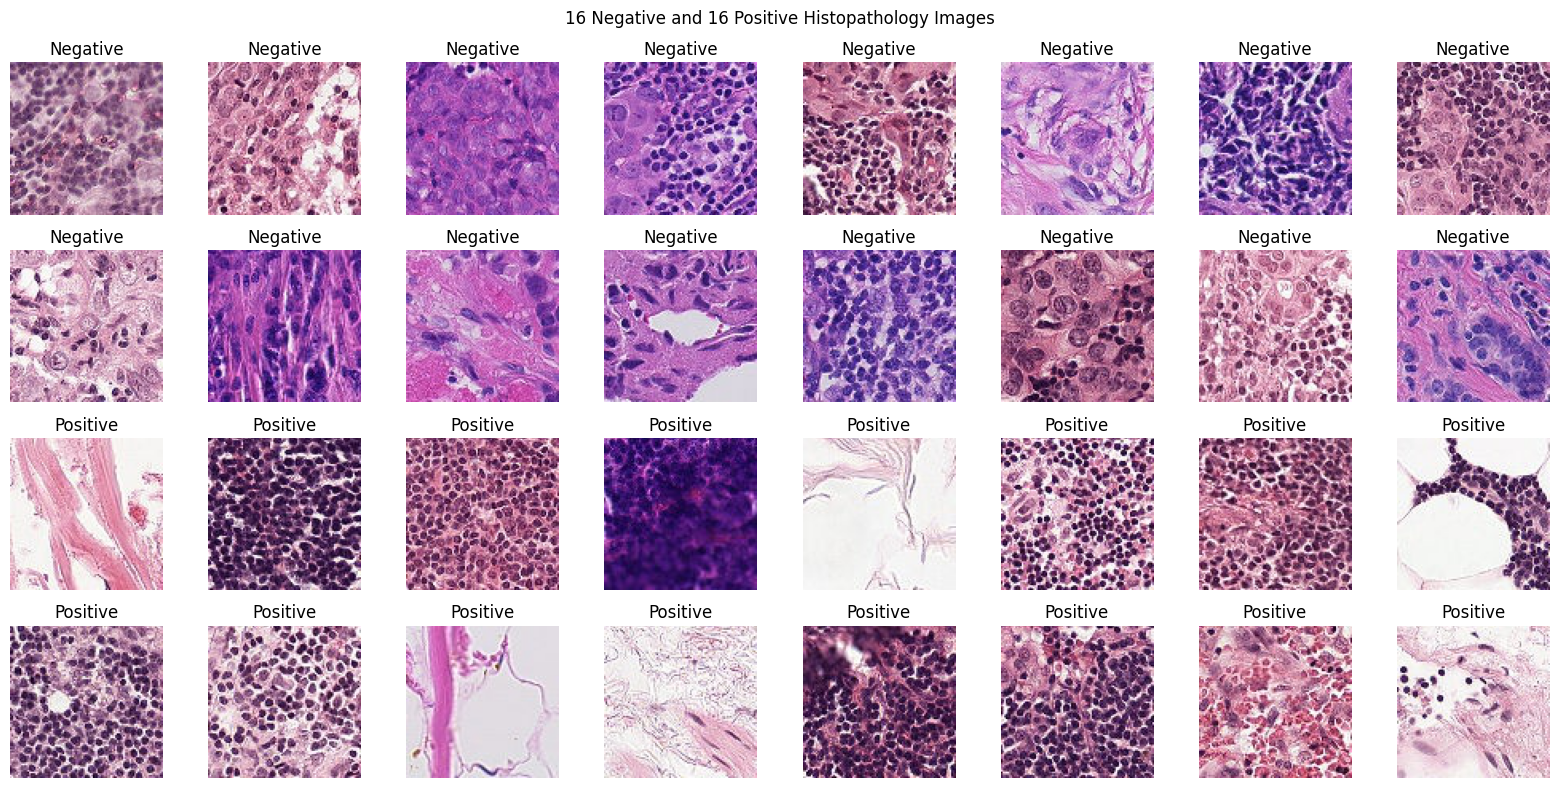

In [19]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Path to the extracted training images directory
train_dir = "/content/data/patchcamelyon/train"

# Select 16 positive and 16 negative image IDs
positive_ids = labels[labels["label"] == 1]["id"].sample(16, random_state=42)
negative_ids = labels[labels["label"] == 0]["id"].sample(16, random_state=42)

selected_ids = list(positive_ids) + list(negative_ids)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for i, image_id in enumerate(selected_ids):
    image_path = os.path.join(train_dir, f"{image_id}.tif")

    # Open the image directly from the folder
    if os.path.exists(image_path):
        image = Image.open(image_path)
        axes[i // 8, i % 8].imshow(image)
    else:
        axes[i // 8, i % 8].text(0.5, 0.5, "Missing", ha="center", va="center")

    axes[i // 8, i % 8].axis("off")

    if i < 16:
        axes[i // 8, i % 8].set_title("Negative")
    else:
        axes[i // 8, i % 8].set_title("Positive")

plt.suptitle("16 Negative and 16 Positive Histopathology Images")
plt.tight_layout()
plt.show()

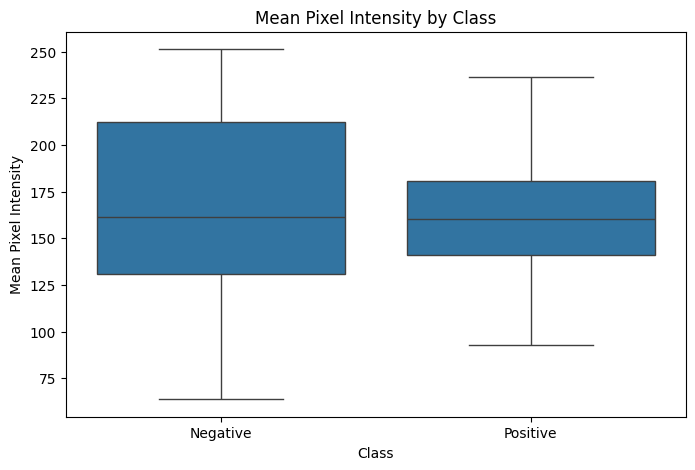

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Sample 100 positive and 100 negative image IDs
positive_sample = labels[labels["label"] == 1].sample(100, random_state=42)
negative_sample = labels[labels["label"] == 0].sample(100, random_state=42)

intensities = []
class_labels = []

train_dir = "/content/data/patchcamelyon/train"

for class_data, class_name in [
    (negative_sample, "Negative"),
    (positive_sample, "Positive")
]:
    for image_id in class_data["id"]:
        image_path = os.path.join(train_dir, f"{image_id}.tif")

        if os.path.exists(image_path):
            # Open image directly from directory
            image = Image.open(image_path).convert("RGB")
            mean_intensity = np.array(image).mean()

            intensities.append(mean_intensity)
            class_labels.append(class_name)

intensity_data = pd.DataFrame({
    "Class": class_labels,
    "Mean Pixel Intensity": intensities
})

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=intensity_data,
    x="Class",
    y="Mean Pixel Intensity"
)

plt.title("Mean Pixel Intensity by Class")
plt.show()